# 03 · When is a detection unmatched?

[Run this notebook in your browser ↗](https://jltobias.github.io/JupyterLite-Global-Fishing-Watch-and-Dark-Vessels/lab/index.html?path=03_matching_and_uncertainty.ipynb)

**Evidence: synthetic positions and invented identifiers.** Explore how a matching rule creates an unmatched category. None of the positions identify real vessels.

Context: [GFW SAR product definitions](https://api-doc.globalfishingwatch.org/our-apis/documentation/docs/v3/4wings/). This transparent teaching algorithm is not GFW's matching algorithm.

Run the setup cell first. Browser Python downloads numerical packages on first use. Core exercises use bundled files; live access is optional. Export your notebook to preserve work.

In [1]:
import sys
if sys.platform == "emscripten":
    import micropip
    await micropip.install(["numpy", "pandas", "matplotlib", "scipy", "plotly"])
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import oceanlab as lab
from IPython.display import display
print("Runtime:", sys.version.split()[0], "| NumPy:", np.__version__, "| pandas:", pd.__version__)

Runtime: 3.13.14 | NumPy: 2.3.3 | pandas: 2.3.2


## A crowded patch of sea
We invent ten AIS candidate positions and ten SAR detections. Positions are assumed to have been projected to acquisition time. `minute` represents the time offset of supporting evidence. Real analysis must propagate vessel motion and location uncertainty, including SAR displacement effects.

,lon,lat,minute,match,distance_km
0,12.404613,54.627730,0.0,demo-0,0.264188
1,12.027973,54.716871,0.0,demo-1,0.166389
2,12.305539,54.655173,0.0,demo-2,0.180853
3,12.214723,54.547154,0.0,demo-3,0.170407
4,12.309355,54.587346,0.0,demo-4,0.729813
5,12.011453,54.522228,0.0,demo-5,0.417860
6,12.024955,54.561437,0.0,demo-6,0.184159
7,12.420000,54.720000,0.0,None,NaN
8,12.080000,54.510000,0.0,None,NaN
9,12.250000,54.700000,0.0,None,NaN


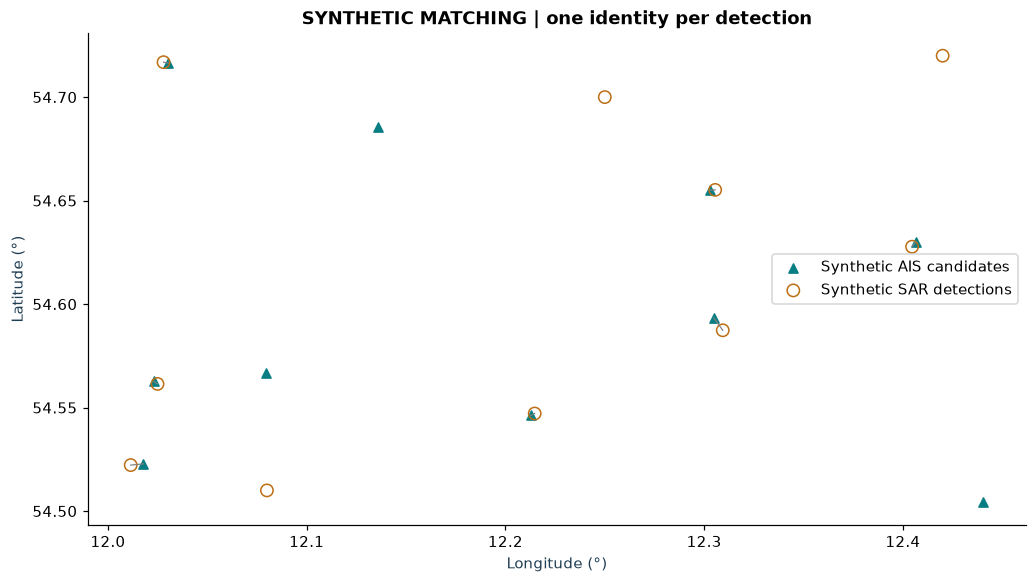

In [2]:
sar, ais = lab.matching_demo()
MAX_KM, MAX_MINUTES = 3.0, 15.0
matched = lab.match_points(sar, ais, max_km=MAX_KM, max_minutes=MAX_MINUTES)
display(matched)
fig, ax = plt.subplots()
ax.scatter(ais.lon, ais.lat, marker="^", c="#087e83", label="Synthetic AIS candidates")
ax.scatter(sar.lon, sar.lat, marker="o", facecolors="none", edgecolors="#bd6e13", s=65, label="Synthetic SAR detections")
for row in matched.dropna(subset=["match"]).itertuples():
    a = ais[ais.id == row.match].iloc[0]
    ax.plot([row.lon,a.lon], [row.lat,a.lat], color="gray", lw=.8)
ax.set(xlabel="Longitude (°)", ylabel="Latitude (°)", title="SYNTHETIC MATCHING | one identity per detection")
ax.legend(); plt.show()

## Sensitivity is part of the result
The algorithm enforces one-to-one matches and allows an unmatched choice. It maximizes valid matches and then minimizes normalized distance-plus-time cost. It has no truth labels for the three added detections: a plausible correspondence is not a verified identity.

,distance_gate_km,matched,unmatched
0,0.25,4,6
1,0.50,6,4
2,1.00,7,3
3,2.00,7,3
4,3.00,7,3
5,5.00,8,2
6,10.00,9,1


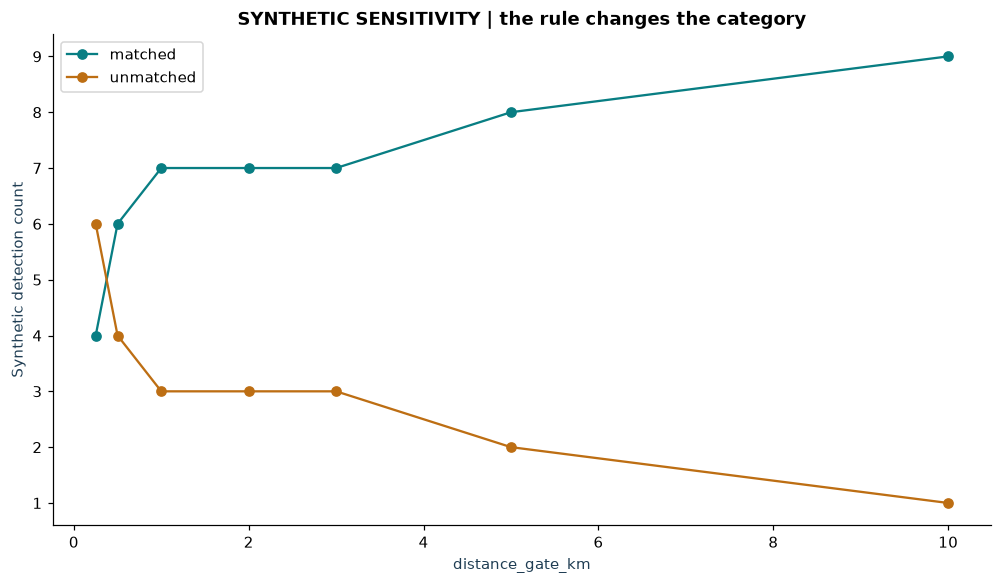

In [3]:
rows=[]
for km in [.25,.5,1,2,3,5,10]:
    result=lab.match_points(sar,ais,max_km=km,max_minutes=MAX_MINUTES)
    rows.append({"distance_gate_km":km,"matched":result.match.notna().sum(),"unmatched":result.match.isna().sum()})
sensitivity=pd.DataFrame(rows)
display(sensitivity)
ax=sensitivity.plot(x="distance_gate_km",y=["matched","unmatched"],marker="o",color=["#087e83","#bd6e13"])
ax.set(ylabel="Synthetic detection count",title="SYNTHETIC SENSITIVITY | the rule changes the category")
plt.show()

## A defensible interpretation
Change the time gate while holding distance fixed. What happens when you require evidence within one minute? Could an apparently unmatched detection become matched with better reception? Explain why a larger gate can reduce unmatched counts while increasing false identity assignments.

**Do not conclude:** the unmatched count is a count of illegal vessels. **Report instead:** the number of candidates without a valid counterpart under the stated rule and evidence coverage.